# Assignment 2 — U-Bolt Damage Propagation

**Task III — Parameter Identification Using POD-NN**


## 1. Inverse Problem Setup

### 1.1 Problem Formulation and Pretrained Surrogate

The objective is to identify the unknown physical parameters governing damage propagation in the U-bolt from time-dependent measurements collected at a single sensor location, $\mathbf{x}_0=(0.5,3)$.

The damage field is approximated using the previously trained POD-NN surrogate:

$$
\widetilde{u}(\mathbf{x},t;\boldsymbol{\mu})
=
\sum_{k=1}^{N}a_k^{\mathrm{NN}}(t,\boldsymbol{\mu})\phi_k(\mathbf{x}),
$$

where $N$ is the number of retained POD modes and $\boldsymbol{\mu}=(\mu_1,\mu_2,\mu_3)\in[0,1]^3$ is the normalized parameter vector.

Given $M$ sensor measurements $m_j=u(\mathbf{x}_0,t_j;\boldsymbol{\mu}_{\mathrm{true}})$, the inverse problem is formulated as

$$
\boxed{
\boldsymbol{\mu}^{*}
=
\underset{\boldsymbol{\mu}\in[0,1]^3}{\operatorname{argmin}}
\frac{1}{M}\sum_{j=1}^{M}
\left[m_j-\widetilde{u}(\mathbf{x}_0,t_j;\boldsymbol{\mu})\right]^2
}
$$

The identified parameters are converted into the physical diffusion coefficient, reaction coefficient, and initial damage location through

$$
D=10^{\mu_1},\qquad
r=10^{\mu_2+2},\qquad
\delta=\mu_3+1.
$$

The POD basis, coefficient scaler, and neural network weights remain fixed throughout the optimization: **only the three physical input parameters are estimated**.


In [16]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import support_functions as sf

ARTIFACTS = Path("artifacts")
DEVICE = "cpu"

# Load POD basis and coefficient scaler
Vn = np.load(ARTIFACTS / "pod_basis.npy")

with np.load(ARTIFACTS / "scaler.npz") as data:
    scaler = sf.CoefficientScaler(
        minimum=data["minimum"],
        scale=data["scale"]
    )

# Reconstruct the trained architecture
model = sf.build_model(
    input_dim=4,
    output_dim=Vn.shape[1],
    hidden_layers=(128,) * 5,
    activation="silu",
    device=DEVICE)

# Load pretrained weights
checkpoint = torch.load(
    ARTIFACTS / "pod_nn_model.pt",
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["state_dict"])

model.eval()
model.requires_grad_(False)

print(f"POD basis: {Vn.shape}")
print(f"Coefficient scaler: {scaler.minimum.shape}")
print("Pretrained POD-NN loaded successfully.")


POD basis: (6636, 50)
Coefficient scaler: (50,)
Pretrained POD-NN loaded successfully.



### 1.2 FEM Sensor Observation Operator

The POD-NN predicts reduced coefficients, whereas the sensor measures the physical damage field at $\mathbf{x}_0$. Therefore, a point-evaluation operator $H_{\mathbf{x}_0}$ is required to map the reduced representation to the observed quantity.

Since the POD modes belong to the original finite element space, their values at the sensor location are computed through **FEM interpolation**, rather than nearest-node sampling.

Let $V_N\in\mathbb{R}^{N_h\times N}$ denote the POD basis and $\mathbf{a}^{\mathrm{NN}}\in\mathbb{R}^{N}$ the predicted coefficient vector. The sensor prediction is

$$
\widetilde{u}(\mathbf{x}_0,t;\boldsymbol{\mu})
=
H_{\mathbf{x}_0}V_N\mathbf{a}^{\mathrm{NN}}(t,\boldsymbol{\mu}).
$$

As both the mesh and POD basis are fixed, the observation vector can be precomputed:

$$
\mathbf{h}_{\mathbf{x}_0}^{T}
=
H_{\mathbf{x}_0}V_N
\in\mathbb{R}^{1\times N}.
$$

Consequently,

$$
\boxed{
\widetilde{u}(\mathbf{x}_0,t;\boldsymbol{\mu})
=
\mathbf{h}_{\mathbf{x}_0}^{T}
\mathbf{a}^{\mathrm{NN}}(t,\boldsymbol{\mu})
}
$$

This reduces each sensor evaluation to a neural network prediction followed by a dot product, **avoiding reconstruction of the full $N_h=6636$-dimensional damage field** during optimization.


In [3]:

from dlroms.cores import CPU, GPU

# Reconstruct the original FEM space
mesh, Vh = sf.build_ubolt_mesh(stepsize=0.05, knots=30)

# Sensor location
x0 = (0.5, 3.0)

# FEM point-evaluation operator
sensor_evaluator = sf.build_damage_evaluator(
    mesh, Vh, x0=x0, device=CPU
)

# Precompute the observation of each POD mode
with torch.no_grad():
    sensor_modes = sensor_evaluator(
        torch.as_tensor(Vn.T.copy(), dtype=torch.float32)
    ).reshape(-1).cpu().numpy()

assert Vh.dim() == Vn.shape[0]
assert sensor_modes.shape == (Vn.shape[1],)

print(f"FEM degrees of freedom: {Vh.dim()}")
print(f"Retained POD modes: {Vn.shape[1]}")
print(f"Sensor position: {x0}")
print(f"Observation vector: {sensor_modes.shape}")


FEM degrees of freedom: 6636
Retained POD modes: 50
Sensor position: (0.5, 3.0)
Observation vector: (50,)



### 1.3 Sensor Measurements and Forward Prediction

The available dataset contains $M=41$ measurements of the local damage at $\mathbf{x}_0=(0.5,3)$, sampled at uniform intervals $\Delta t=5\times10^{-4}$ over $[0,T]$, with $T=0.02$.

For each candidate parameter vector $\boldsymbol{\mu}$, the pretrained POD-NN is evaluated at all measurement times, producing the coefficient matrix

$$
A_{\mathrm{NN}}(\boldsymbol{\mu})
\in\mathbb{R}^{M\times N}.
$$

Using the precomputed observation vector, the complete predicted sensor signal is

$$
\boxed{
\widetilde{\mathbf{m}}(\boldsymbol{\mu})
=
A_{\mathrm{NN}}(\boldsymbol{\mu})\mathbf{h}_{\mathbf{x}_0}
}
$$

Thus, each objective-function evaluation requires only a batched NN inference and a matrix-vector product, making the surrogate suitable for repeated evaluations within an optimization routine.


Measurements: 41
Time interval: [0.0000, 0.0200]
Damage range: [0.0000, 0.8580]


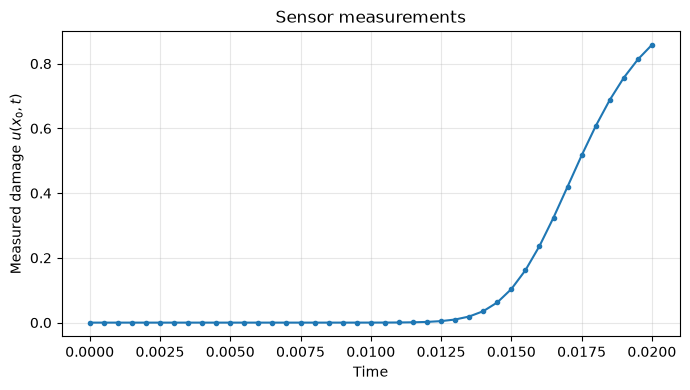

In [4]:

import gdown

sensor_path = Path("damage_measurements.npy")

if not sensor_path.exists():
    gdown.download(
        id="16htWP91l5tpgK3ZYqjK-GHvVpW7lr2a5",
        output=str(sensor_path),
        quiet=False
    )

measurements = np.load(sensor_path).reshape(-1)

dt = 5e-4
sensor_times = np.arange(len(measurements)) * dt

assert len(measurements) == 41
assert np.all(np.isfinite(measurements))

print(f"Measurements: {len(measurements)}")
print(f"Time interval: [{sensor_times[0]:.4f}, {sensor_times[-1]:.4f}]")
print(f"Damage range: [{measurements.min():.4f}, {measurements.max():.4f}]")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sensor_times, measurements, "o-", markersize=3)
ax.set(
    xlabel="Time",
    ylabel=r"Measured damage $u(x_0,t)$",
    title="Sensor measurements"
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Initial MSE: 8.151100e-02


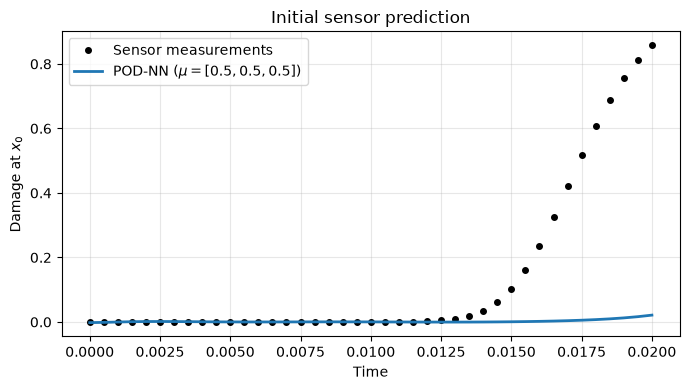

In [5]:

def predict_sensor(mu):
    """Return surrogate damage observations for parameters mu using the loaded POD-NN and sensor operator."""
    mu = np.asarray(mu, dtype=float).reshape(1, 3)

    X = sf.make_nn_inputs(mu, sensor_times)
    A = sf.predict_coefficients(model, X, scaler)

    return A @ sensor_modes


# Initial prediction at the center of the parameter domain
mu_initial = np.full(3, 0.5)
prediction_initial = predict_sensor(mu_initial)

assert prediction_initial.shape == measurements.shape
assert np.all(np.isfinite(prediction_initial))

initial_mse = np.mean((prediction_initial - measurements)**2)
print(f"Initial MSE: {initial_mse:.6e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sensor_times, measurements, "ko", markersize=4,
        label="Sensor measurements")
ax.plot(sensor_times, prediction_initial, "-", linewidth=2,
        label=r"POD-NN ($\mu=[0.5,0.5,0.5]$)")

ax.set(
    xlabel="Time",
    ylabel=r"Damage at $x_0$",
    title="Initial sensor prediction"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 2. Parameter Identification

### 2.1 Objective Function and Optimization Strategy

The unknown parameters are estimated by minimizing the mean squared error between the measured sensor signal and the POD-NN prediction:

$$
J(\boldsymbol{\mu}) =
\frac{1}{M}\sum_{j=1}^{M}
\left[\widetilde{u}(\mathbf{x}_0,t_j;\boldsymbol{\mu})-m_j\right]^2,
\qquad \boldsymbol{\mu}\in[0,1]^3.
$$

The optimization is performed in the normalized parameter space, ensuring comparable parameter scales and simple box constraints.

Since the surrogate introduces a nonlinear dependence on the parameters, the objective may exhibit multiple local minima. We therefore adopt a two-stage identification strategy:

1. **Coarse parameter exploration:** evaluate the objective on a $3\times3\times3$ grid to identify promising regions and inspect the variability of the predicted sensor signals.
2. **Multi-start local optimization:** apply L-BFGS-B from the five best grid candidates and ten additional uniformly sampled initializations, retaining the solution with the lowest objective value.

The POD basis and neural network weights remain fixed throughout the procedure.


Top 5 grid candidates:
mu = [1.  0.5 0. ], MSE = 9.408399e-03, final damage = 0.6429
mu = [0.  1.  0.5], MSE = 1.630674e-02, final damage = 0.9742
mu = [1.  0.5 0.5], MSE = 1.974848e-02, final damage = 0.4529
mu = [0. 1. 1.], MSE = 3.781508e-02, final damage = 0.5085
mu = [1.  0.5 1. ], MSE = 5.953021e-02, final damage = 0.1700


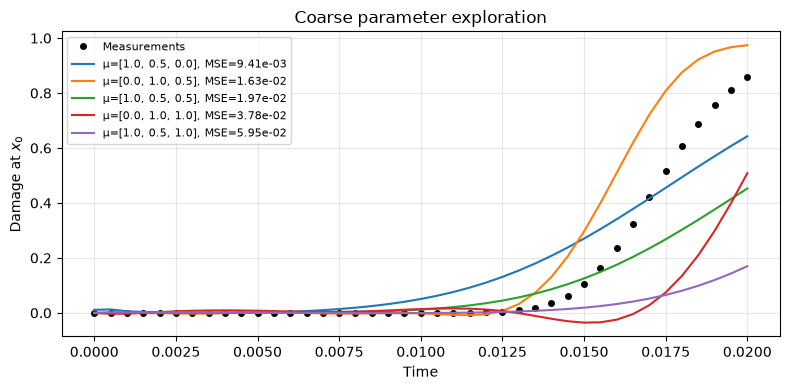

In [6]:

from itertools import product

# Coarse exploration of the normalized parameter domain
mu_values = [0.0, 0.5, 1.0]
candidates = np.array(list(product(mu_values, repeat=3)))

grid_results = []

for mu in candidates:
    prediction = predict_sensor(mu)
    mse = np.mean((prediction - measurements)**2)
    grid_results.append((mse, mu, prediction))

grid_results.sort(key=lambda item: item[0])

print("Top 5 grid candidates:")
for mse, mu, prediction in grid_results[:5]:
    print(
        f"mu = {np.round(mu, 3)}, "
        f"MSE = {mse:.6e}, "
        f"final damage = {prediction[-1]:.4f}"
    )

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(sensor_times, measurements, "ko",
        markersize=4, label="Measurements")

for mse, mu, prediction in grid_results[:5]:
    ax.plot(sensor_times, prediction,
            label=f"μ={mu.tolist()}, MSE={mse:.2e}")

ax.set(
    xlabel="Time",
    ylabel=r"Damage at $x_0$",
    title="Coarse parameter exploration"
)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

from scipy.optimize import minimize

def objective(mu):
    """Return the measurement-mismatch objective for the candidate physical parameters mu."""
    residuals = predict_sensor(mu) - measurements
    return float(np.mean(residuals**2))


# Five best grid candidates + ten random initializations
rng = np.random.default_rng(42)

grid_starts = np.array([item[1] for item in grid_results[:5]])
random_starts = rng.uniform(0, 1, size=(10, 3))
initial_guesses = np.vstack([grid_starts, random_starts])

bounds = [(0.0, 1.0)] * 3
optimization_results = []

for i, mu0 in enumerate(initial_guesses):
    res = minimize(
        objective,
        x0=mu0,
        method="L-BFGS-B",
        bounds=bounds,
        options={
            "maxiter": 500,
            "ftol": 1e-12,
            "gtol": 1e-7,
            "eps": 1e-4
        }
    )

    optimization_results.append(res)

    print(
        f"Start {i+1:02d}: "
        f"MSE={res.fun:.8e}, "
        f"mu={np.round(res.x, 4)}, "
        f"success={res.success}"
    )

# Select the best solution
best_result = min(
    optimization_results,
    key=lambda res: res.fun
)

mu_opt = best_result.x
mse_opt = best_result.fun

# Convert normalized parameters to physical quantities
D_opt = 10**mu_opt[0]
r_opt = 10**(mu_opt[1] + 2)
delta_opt = mu_opt[2] + 1

print("\nOptimal parameters:")
print(f"mu*   = {np.round(mu_opt, 6)}")
print(f"D     = {D_opt:.5f}")
print(f"r     = {r_opt:.5f}")
print(f"delta = {delta_opt:.5f}")
print(f"MSE   = {mse_opt:.8e}")


Start 01: MSE=4.27522064e-05, mu=[0.1302 0.8931 0.3289], success=True
Start 02: MSE=3.28222704e-05, mu=[0.1877 0.9065 0.5335], success=True
Start 03: MSE=9.27360543e-06, mu=[0.409  0.891  0.8823], success=True
Start 04: MSE=9.23755761e-06, mu=[0.409  0.891  0.8828], success=True
Start 05: MSE=7.68235896e-06, mu=[0.4022 0.894  0.8856], success=True
Start 06: MSE=8.74209945e-06, mu=[0.4066 0.8919 0.8826], success=True
Start 07: MSE=6.50491484e-06, mu=[0.401  0.8966 0.8982], success=True
Start 08: MSE=3.57557437e-05, mu=[0.1954 0.8973 0.4976], success=True
Start 09: MSE=9.01965177e-06, mu=[0.4088 0.8912 0.8835], success=True
Start 10: MSE=3.11091790e-05, mu=[0.1704 0.9106 0.5225], success=False
Start 11: MSE=4.42985838e-05, mu=[0.1265 0.892  0.3128], success=True
Start 12: MSE=8.30159479e-06, mu=[0.4162 0.8915 0.9014], success=True
Start 13: MSE=1.00930029e-05, mu=[0.4044 0.8912 0.8737], success=True
Start 14: MSE=3.16030528e-05, mu=[0.1764 0.9062 0.5103], success=True
Start 15: MSE=3.170


### 2.2 Identification Results

The best solution is selected by minimizing the sensor reconstruction MSE across all optimization runs. The corresponding normalized parameters are converted into the physical diffusion coefficient $D$, reaction coefficient $r$, and initial damage location $\delta$.

The quality of the identified solution is assessed through:

- **MSE and RMSE:** absolute sensor reconstruction accuracy.
- **Relative $L^2$ error:** temporal signal discrepancy normalized by the measured signal norm.
- **Normalized RMSE:** RMSE expressed as a percentage of the maximum measured damage.
- **Maximum absolute error:** largest individual discrepancy between measured and predicted damage.

The relative temporal error is defined as

$$
e_{\mathrm{rel}} =
\frac{
\left\|\widetilde{\mathbf{m}}(\boldsymbol{\mu}^*)-\mathbf{m}\right\|_2
}{
\left\|\mathbf{m}\right\|_2
}.
$$

These metrics quantify the agreement at the sensor location, but do not independently establish the accuracy of the reconstructed spatial field or uniqueness of the identified parameters.


Identification results:
mu*                  = [0.401006 0.896568 0.898164]
D                    = 2.51771
r                    = 788.07508
delta                = 1.89816

MSE                  = 6.50491484e-06
RMSE                 = 2.55047344e-03
Relative L2 error    = 0.8783%
NRMSE (peak)         = 0.2973%
Maximum absolute err = 6.33525848e-03
Max error / peak     = 0.7384%


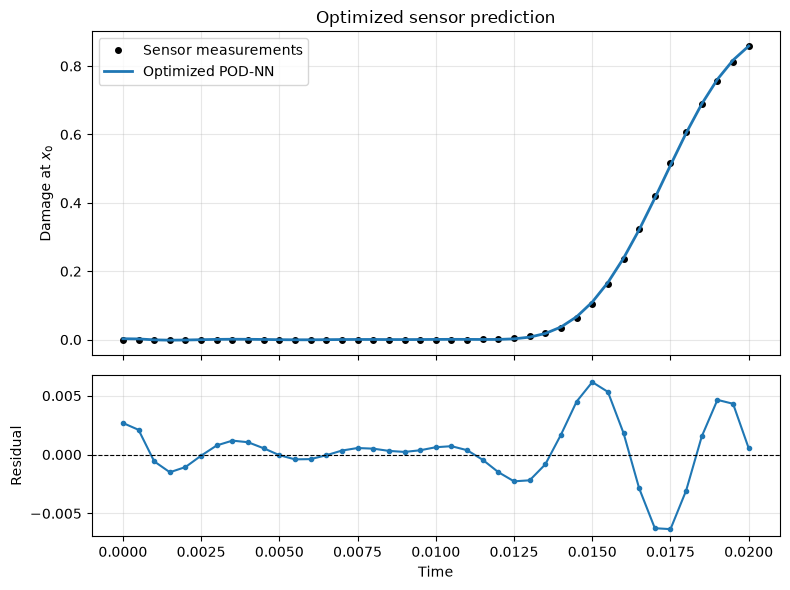

In [8]:

prediction_opt = predict_sensor(mu_opt)
residuals = prediction_opt - measurements

# Sensor reconstruction metrics
mse = np.mean(residuals**2)
rmse = np.sqrt(mse)
max_abs_error = np.max(np.abs(residuals))

relative_l2 = (
    np.linalg.norm(residuals) /
    np.linalg.norm(measurements) * 100
)

peak_damage = np.max(np.abs(measurements))
nrmse = rmse / peak_damage * 100
max_error_pct = max_abs_error / peak_damage * 100

print("Identification results:")
print(f"mu*                  = {np.round(mu_opt, 6)}")
print(f"D                    = {D_opt:.5f}")
print(f"r                    = {r_opt:.5f}")
print(f"delta                = {delta_opt:.5f}")
print()
print(f"MSE                  = {mse:.8e}")
print(f"RMSE                 = {rmse:.8e}")
print(f"Relative L2 error    = {relative_l2:.4f}%")
print(f"NRMSE (peak)         = {nrmse:.4f}%")
print(f"Maximum absolute err = {max_abs_error:.8e}")
print(f"Max error / peak     = {max_error_pct:.4f}%")

fig, axes = plt.subplots(
    2, 1, figsize=(8, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0].plot(sensor_times, measurements, "ko",
             markersize=4, label="Sensor measurements")
axes[0].plot(sensor_times, prediction_opt, "-",
             linewidth=2, label="Optimized POD-NN")
axes[0].set_ylabel(r"Damage at $x_0$")
axes[0].set_title("Optimized sensor prediction")
axes[0].legend()

axes[1].plot(sensor_times, residuals, "o-",
             markersize=3)
axes[1].axhline(0, color="black", linestyle="--",
                linewidth=0.8)
axes[1].set(
    xlabel="Time",
    ylabel="Residual"
)

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 2.3 Discussion

The multi-start optimization provides an estimate of the physical parameters that reproduces the observed temporal damage evolution using only the pretrained POD-NN surrogate, without requiring additional full-order simulations.

The quality of the identification is evaluated by comparing the optimized prediction with the measurements and examining the residuals over time.

However, the nonlinear inverse problem may admit distinct parameter combinations producing similar sensor responses. Consequently, a small reconstruction error does not necessarily imply that the true physical parameters have been uniquely recovered.

This limitation motivates the spatial comparison presented in the following section, where the reconstructed damage fields associated with different identified parameter configurations are examined.



## 3. Spatial Reconstruction and Identifiability

### 3.1 Spatial Reconstruction

Once the optimal parameters have been identified, the POD-NN can reconstruct the complete damage field over the U-bolt geometry:

$$
\widetilde{\mathbf{u}}(t;\boldsymbol{\mu}^{*})
=
V_N\mathbf{a}^{\mathrm{NN}}(t,\boldsymbol{\mu}^{*}).
$$

Although the inverse problem relies exclusively on measurements at $\mathbf{x}_0=(0.5,3)$, the surrogate provides a spatially distributed prediction of the damage evolution.

We visualize the reconstructed field over the observation interval $[0,T]$, highlighting the sensor location and its predicted damage value. A fixed color scale is adopted to facilitate comparisons across time.

Importantly, this represents a **ROM-based spatial prediction**, rather than an independently validated FOM reconstruction of the unknown system.


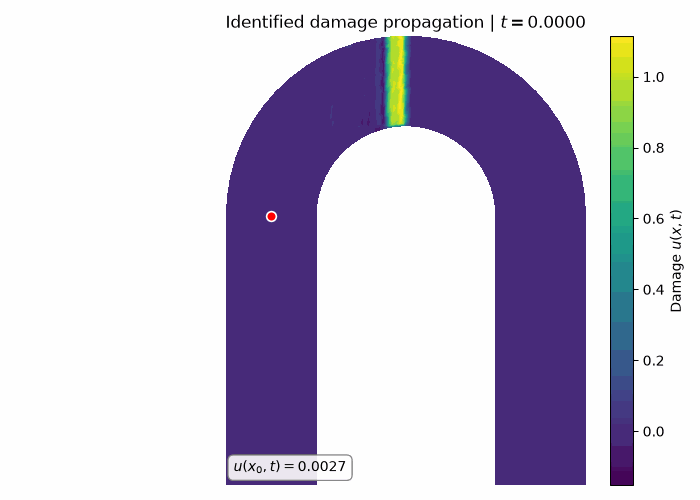

In [9]:

import matplotlib as mpl
import dlroms.fespaces as fe
from dlroms.fespaces import gifs
from IPython.display import Image, display

# Reconstruct the optimal damage trajectory
X_opt = sf.make_nn_inputs(mu_opt.reshape(1, -1), sensor_times)
A_opt = sf.predict_coefficients(model, X_opt, scaler)
u_opt = sf.reconstruct_pod(A_opt, Vn)

sensor_opt = A_opt @ sensor_modes

# Fixed color scale over the complete trajectory
field_min = min(0.0, float(u_opt.min()))
field_max = max(1.0, float(u_opt.max()))
levels = np.linspace(field_min, field_max, 120)

cmap = plt.get_cmap("viridis")
norm = mpl.colors.Normalize(vmin=field_min, vmax=field_max)

def draw_damage_frame(i):
    """Draw the identified-parameter damage field at animation frame i."""
    fig, ax = plt.subplots(figsize=(7, 5))
    plt.sca(ax)

    fe.plot(
        u_opt[i], Vh,
        cmap=cmap,
        levels=levels
    )

    ax.plot(
        *x0, "ro", markersize=7,
        markeredgecolor="white", markeredgewidth=1.2
    )

    ax.set_title(
        rf"Identified damage propagation | $t={sensor_times[i]:.4f}$"
    )

    ax.text(
        0.02, 0.03,
        rf"$u(x_0,t)={sensor_opt[i]:.4f}$",
        transform=ax.transAxes,
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.9,
                  edgecolor="gray", boxstyle="round,pad=0.4")
    )

    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    fig.colorbar(sm, ax=ax, fraction=0.045, pad=0.04,
                 label="Damage $u(x,t)$")

    ax.set_aspect("equal")
    plt.tight_layout()

gifs.save(draw_damage_frame, len(sensor_times), "identified_damage.gif")
display(Image(filename="identified_damage.gif"))



### 3.2 Spatial Ambiguity of the Inverse Problem

A low sensor reconstruction error does not necessarily guarantee unique parameter identification or accurate recovery of the entire spatial field.

To investigate this limitation, we compare the optimal solution with a distinct parameter configuration obtained from the multi-start optimization.

The alternative candidate is selected according to its distance from the optimal parameters and its sensor reconstruction error, rather than by an arbitrary optimization-run index.

For both configurations, the POD-NN reconstructs the damage field at the final observation time $T=0.02$. We then examine the absolute pointwise difference:

$$
d(\mathbf{x}) =
\left|
\widetilde{u}(\mathbf{x},T;\boldsymbol{\mu}^{*})
-
\widetilde{u}(\mathbf{x},T;\boldsymbol{\mu}_{\mathrm{alt}})
\right|.
$$

This comparison allows us to assess whether different parameter configurations with similar sensor responses may produce significantly different spatial damage distributions.


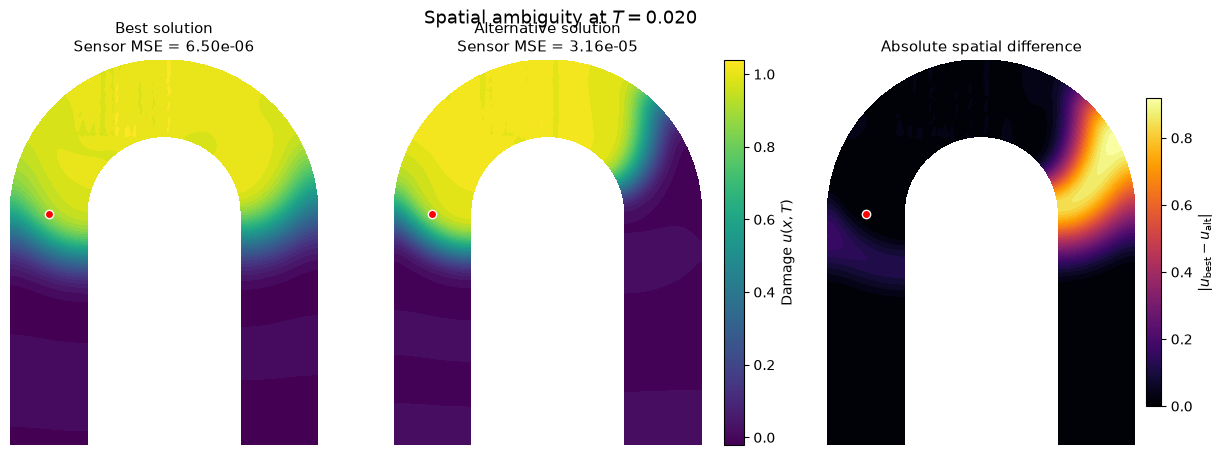

Best parameters:        [0.401006 0.896568 0.898164]
Alternative parameters: [0.176431 0.906241 0.510301]
Parameter distance:     0.4483
Best sensor MSE:        6.50491484e-06
Alternative sensor MSE: 3.16030528e-05
Maximum field difference: 0.9179


In [12]:

# Select a distinct alternative from the multi-start solutions
min_distance = 0.10

alternatives = [
    res for res in optimization_results
    if res.success
    and np.all(np.isfinite(res.x))
    and np.isfinite(res.fun)
    and np.linalg.norm(res.x - mu_opt) >= min_distance
]

if not alternatives:
    raise RuntimeError(
        "No sufficiently distinct alternative found among the optimization results."
    )

alternative_result = min(alternatives, key=lambda res: res.fun)
mu_alt = alternative_result.x

# Reconstruct the alternative trajectory
X_alt = sf.make_nn_inputs(mu_alt.reshape(1, -1), sensor_times)
A_alt = sf.predict_coefficients(model, X_alt, scaler)
u_alt = sf.reconstruct_pod(A_alt, Vn)

# Final-time fields, without clipping
u_best_T = u_opt[-1]
u_alt_T = u_alt[-1]
difference_T = np.abs(u_best_T - u_alt_T)

# Sensor reconstruction errors
prediction_alt = A_alt @ sensor_modes
mse_best = np.mean((sensor_opt - measurements)**2)
mse_alt = np.mean((prediction_alt - measurements)**2)

# Common damage scale and separate difference scale
damage_min = min(float(u_best_T.min()), float(u_alt_T.min()), 0.0)
damage_max = max(float(u_best_T.max()), float(u_alt_T.max()), 1.0)

damage_levels = np.linspace(damage_min, damage_max, 120)
diff_levels = np.linspace(
    0.0, max(float(difference_T.max()), 1e-12), 120
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fields = [u_best_T, u_alt_T, difference_T]
titles = [
    f"Best solution\nSensor MSE = {mse_best:.2e}",
    f"Alternative solution\nSensor MSE = {mse_alt:.2e}",
    "Absolute spatial difference"
]

for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    plt.sca(ax)

    fe.plot(
        field, Vh,
        cmap="viridis" if i < 2 else "inferno",
        levels=damage_levels if i < 2 else diff_levels
    )

    ax.plot(
        *x0, "ro", markersize=6,
        markeredgecolor="white", markeredgewidth=1
    )
    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")

damage_sm = mpl.cm.ScalarMappable(
    norm=mpl.colors.Normalize(damage_min, damage_max),
    cmap="viridis"
)
diff_sm = mpl.cm.ScalarMappable(
    norm=mpl.colors.Normalize(0, max(float(difference_T.max()), 1e-12)),
    cmap="inferno"
)

fig.colorbar(
    damage_sm, ax=axes[:2],
    fraction=0.035, pad=0.03,
    label=r"Damage $u(x,T)$"
)
fig.colorbar(
    diff_sm, ax=axes[2],
    fraction=0.045, pad=0.03,
    label=r"$|u_{\mathrm{best}}-u_{\mathrm{alt}}|$"
)

fig.suptitle(
    rf"Spatial ambiguity at $T={sensor_times[-1]:.3f}$",
    fontsize=13
)
plt.show()

print("Best parameters:       ", np.round(mu_opt, 6))
print("Alternative parameters:", np.round(mu_alt, 6))
print(f"Parameter distance:     {np.linalg.norm(mu_alt - mu_opt):.4f}")
print(f"Best sensor MSE:        {mse_best:.8e}")
print(f"Alternative sensor MSE: {mse_alt:.8e}")
print(f"Maximum field difference: {difference_T.max():.4f}")


## 4. Discussion and Conclusions

The inverse problem uses the POD-NN surrogate developed in Tasks I–II to estimate three normalized parameters from 41 measurements at the single sensor location $\mathbf{x}_0=(0.5,3)$. Precomputing the FEM observation of the POD modes makes each objective evaluation a batched neural-network prediction followed by a matrix-vector product, without reconstructing the full spatial field or running additional FOM simulations during optimization.

The coarse exploration and 15-start L-BFGS-B search yield the best identified configuration

$$
\boldsymbol{\mu}^{*}=(0.401006,\;0.896568,\;0.898164),
$$

corresponding to $D^{*}=2.51771$, $r^{*}=788.07508$, and $\delta^{*}=1.89816$. The predicted sensor signal achieves an MSE of $6.5049\times10^{-6}$, an RMSE of $2.5505\times10^{-3}$, and a relative temporal $L^2$ error of $0.8783\%$. The peak-normalized RMSE is $0.2973\%$, while the maximum absolute discrepancy is $0.00634$. These results demonstrate accurate reproduction of the observed signal by the pretrained surrogate.

The multi-start results also contain distinct parameter configurations with small sensor residuals. In Section 3.2, the alternative is selected only among runs reporting successful convergence, requiring a normalized parameter distance of at least $0.10$ from the best solution and retaining the eligible candidate with the lowest sensor MSE. The selected configuration is $\boldsymbol{\mu}_{\mathrm{alt}}=(0.176431,\;0.906241,\;0.510301)$, at a distance of $0.4483$ from the best solution. Its sensor MSE is $3.1603\times10^{-5}$, approximately 4.9 times the best MSE. Both configurations therefore have small absolute sensor residuals, although their fits are not equally accurate.

Despite this agreement with the single-sensor measurements, the reconstructed fields at $T=0.02$ exhibit a maximum absolute pointwise difference of $0.9179$, as shown in the spatial comparison. This provides evidence of practical ambiguity in the surrogate-based reconstruction: distinct configurations returned by successfully terminated optimization runs can fit the available signal reasonably well while predicting substantially different spatial damage distributions. Successful termination alone does not certify the minima mathematically, and these results do not prove structural non-uniqueness or equal agreement with the measurements.

Together, the sensor fit and spatial comparison show why measurement reconstruction and parameter recovery must be assessed separately. The available results support the use of POD-NN for fitting the observed temporal signal, but the unknown true parameters and the corresponding FOM field are unavailable for independent validation. Moreover, the global field-error assessment in Tasks I–II does not by itself establish pointwise surrogate accuracy at this sensor or at the identified configuration.

Additional sensors at complementary spatial locations could help distinguish configurations with similar single-sensor responses. A FOM simulation at the identified parameters would also allow the surrogate prediction to be checked against the full-order model. These checks would strengthen the interpretation of the identified parameters and reconstructed damage evolution beyond the sensor agreement demonstrated here.


In [11]:
ARTIFACTS.mkdir(parents=True, exist_ok=True)

results_path = ARTIFACTS / "inverse_results.npz"

if not results_path.exists():
    np.savez(
        results_path,
        mu_opt=mu_opt,
        D_opt=D_opt,
        r_opt=r_opt,
        delta_opt=delta_opt,
        sensor_times=sensor_times,
        measurements=measurements,
        prediction_opt=prediction_opt,
        mu_alt=mu_alt,
        prediction_alt=prediction_alt,
        mse_best=mse_best,
        mse_alt=mse_alt,
        max_spatial_difference=difference_T.max()
    )

    print("Inverse problem results saved successfully.")

else:
    print(f"Results already exist — skipping: {results_path}")

Results already exist — skipping: artifacts/inverse_results.npz
